<a href="https://colab.research.google.com/github/Ranjitkumarmuduli/tomato-disease-detection/blob/main/06_presentation_assets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Setup
Loads the final model from `app_model/` and the test images, to create presentation figures.

In [ ]:
!pip -q install timm kagglehub
import os, json, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, timm, kagglehub
from PIL import Image
from torchvision import transforms as T
from google.colab import drive
drive.mount('/content/drive')

PROJ = "/content/drive/MyDrive/tomato_project"
APP  = f"{PROJ}/app_model"
base = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
ROOT = f"{base}/plantvillage dataset/color"

CFG = json.load(open(f"{APP}/config.json"))
CLASSES = CFG["classes"]
model = timm.create_model(CFG["model_name"], pretrained=False, num_classes=len(CLASSES))
model.load_state_dict(torch.load(f"{APP}/model.pt", map_location="cpu")); model.eval()
tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(CFG["mean"], CFG["std"])])
short = lambda c: (c.replace("Spider_mites Two-spotted_spider_mite", "Spider mites")
                    .replace("Tomato_Yellow_Leaf_Curl_Virus", "Yellow Leaf Curl")
                    .replace("Tomato_mosaic_virus", "Mosaic virus").replace("_", " "))
print("Model loaded:", CFG["model_name"])

Mounted at /content/drive
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Model loaded: efficientnet_b0


## 2. Testing on input images
12 random **test** images (never seen in training). Each shows the true class, the predicted class
and the confidence. Green title = correct, red = wrong. This is the "testing" slide.

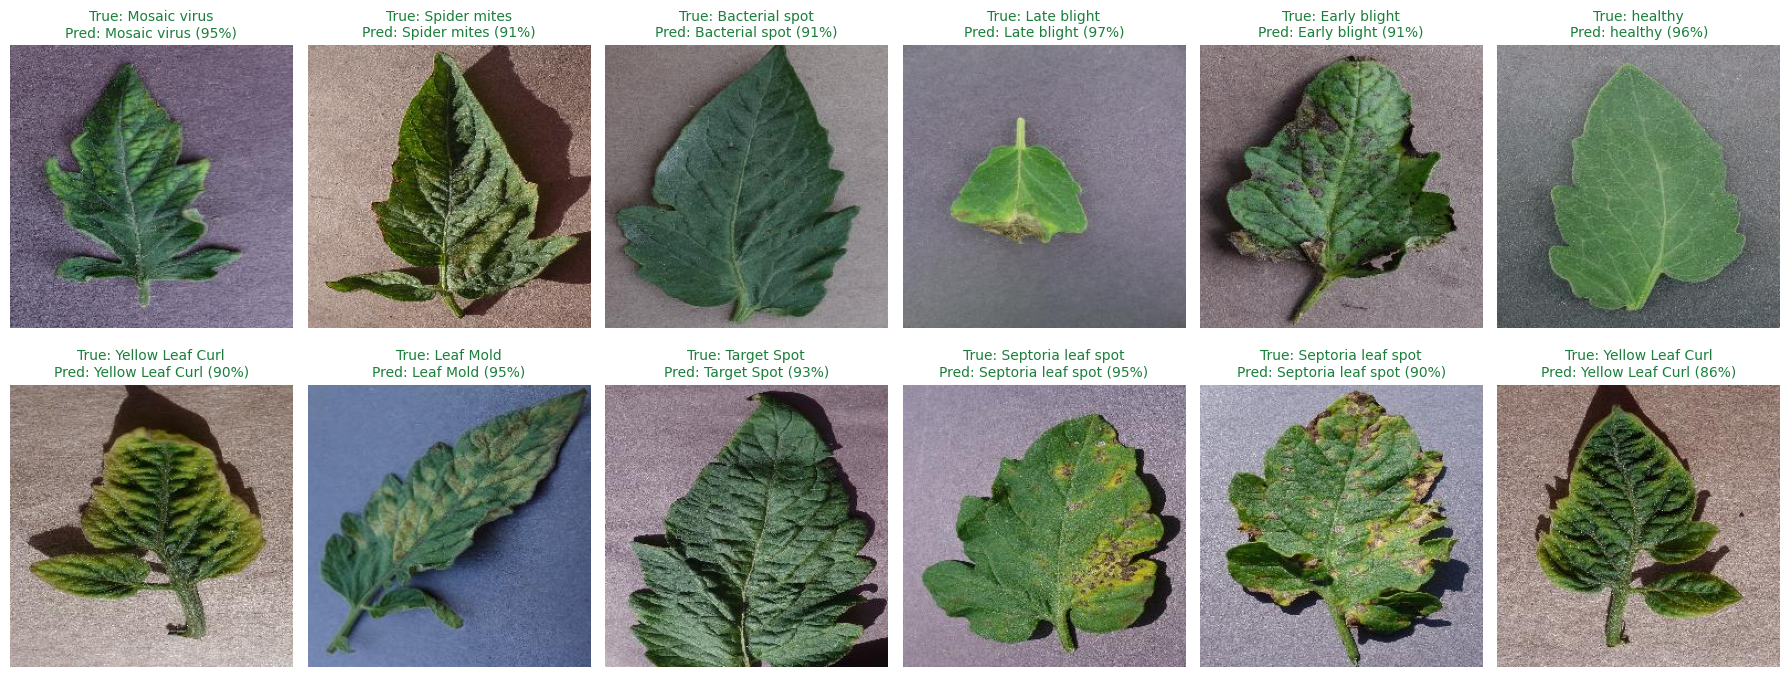

In [ ]:
test_df = pd.read_csv(f"{PROJ}/splits/test.csv")
sample = test_df.groupby("label").sample(1, random_state=7).sample(10, random_state=7)   # one per class
sample = pd.concat([sample, test_df.sample(2, random_state=3)])                           # + 2 random

fig, axes = plt.subplots(2, 6, figsize=(18, 7.2))
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    img = Image.open(f"{ROOT}/{r.relpath}").convert("RGB")
    with torch.no_grad():
        p = torch.softmax(model(tf(img).unsqueeze(0)), 1)[0]
    pred, conf = int(p.argmax()), float(p.max())
    ok = pred == r.label
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"True: {short(CLASSES[r.label])}\nPred: {short(CLASSES[pred])} ({conf:.0%})",
                 fontsize=10, color="#1b7f3b" if ok else "#c62828")
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/test_predictions_grid.png", dpi=200); plt.show()

## 3. Export presentation assets
Collects all figures, result tables and example input images into one zip to download.

In [ ]:
OUT = "/content/ppt_assets"
shutil.rmtree(OUT, ignore_errors=True)
shutil.copytree(f"{PROJ}/figures", f"{OUT}/figures")
shutil.copytree(f"{PROJ}/results", f"{OUT}/results")
shutil.copytree(f"{APP}/examples", f"{OUT}/input_examples")
shutil.copy(f"{APP}/config.json", OUT)
shutil.make_archive("/content/ppt_assets", "zip", OUT)
print(sorted(os.listdir(f"{OUT}/figures")))
from google.colab import files
files.download("/content/ppt_assets.zip")

['accuracy_vs_size.png', 'augmented_samples.png', 'class_distribution.png', 'confusion_matrix_efficientnet_b0.png', 'curves_baseline_cnn.png', 'curves_efficientnet_b0.png', 'curves_mobilenetv3_large_100.png', 'curves_resnet50.png', 'gradcam_efficientnet_b0.png', 'misclassified_efficientnet_b0.png', 'test_predictions_grid.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>